# Step 2 — Baseline: PPO on Walker-v0 with the hand-designed robot

**Setup:** course TD6 hyperparameters (lr 3e-4, γ 0.99, λ 0.95, clip 0.2, 10 epochs, batch 64, 2048 transitions per update), **no reward normalisation**, 1M steps, 8 parallel envs, seed 31.

Training was launched from the terminal (this notebook only analyses the saved run):
```bash
caffeinate -i python ppo.py --env Walker-v0 --robot walker --steps 1000000 --n-envs 8 \
    --vectorization async --seed 31 --out runs/walker_baseline_s31
```

**Robot** (5×5 voxels: 1 rigid, 3 horizontal muscle, 4 vertical muscle, 0 empty) — a rigid back and two legs, seen from the side. It is only a fixed problem to tune PPO and a human reference to beat; it is never part of the evolution.
```
1 1 1 1 1
3 3 3 3 3
3 3 . 3 3
4 4 . 4 4
4 4 . 4 4
```
**Task:** move right as far as possible; reward ≈ forward displacement of the robot per step; episodes of 500 steps.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.insert(0, "..")  # repo root, where ppo.py lives
from ppo import PPOAgent, make_env, load_body, test_agent

RUN = Path("../runs/walker_baseline_s31")
config = json.loads((RUN / "config.json").read_text())
log = pd.read_csv(RUN / "log.csv")
episodes = pd.read_csv(RUN / "episodes.csv")["episode_return"].to_numpy()
body = np.array(config["body"])
print(f"{config['steps']:,} steps, {len(episodes)} episodes, {log['time_s'].iloc[-1] / 60:.1f} min of training")
print(body)

1,000,000 steps, 2120 episodes, 28.9 min of training
[[1 1 1 1 1]
 [3 3 3 3 3]
 [3 3 0 3 3]
 [4 4 0 4 4]
 [4 4 0 4 4]]


## Random reference

What does a "zero" score look like on this task? Same robot, uniformly random actions, 10 episodes.

In [2]:
env = make_env("Walker-v0", {"body": body})
env.action_space.seed(0)
random_returns = []
for ep in range(10):
    env.reset(seed=ep)
    done, total = False, 0.0
    while not done:
        _, r, terminated, truncated, _ = env.step(env.action_space.sample())
        total += r
        done = terminated or truncated
    random_returns.append(total)
env.close()
random_mean, random_std = np.mean(random_returns), np.std(random_returns)
print(f"Random actions: {random_mean:.3f} ± {random_std:.3f} per episode")

/Users/enzo/Desktop/RL/evogym-coevolution/.venv/lib/python3.10/site-packages/evogym/envs/base.py:12: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Random actions: -0.020 ± 0.237 per episode


## Learning curves

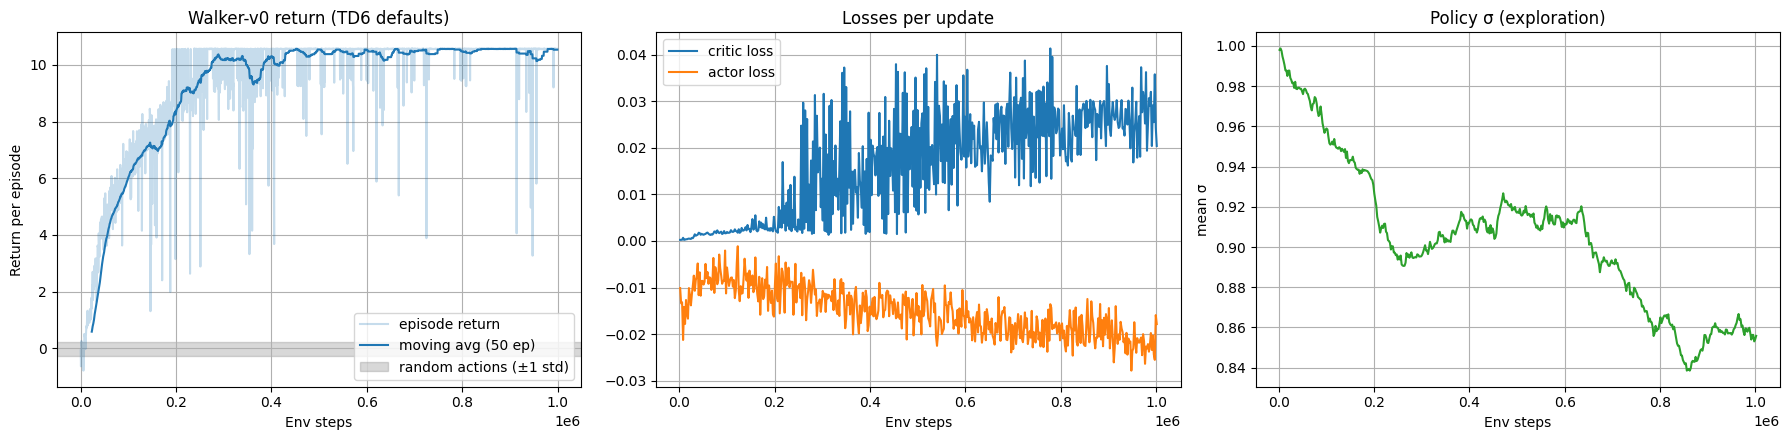

Last 100 episodes: 10.50 ± 0.49 | best moving avg (50): 10.57 | random: -0.02


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
steps_per_episode = config["steps"] / len(episodes)

ax = axes[0]
x = np.arange(len(episodes)) * steps_per_episode
ax.plot(x, episodes, alpha=0.25, color="tab:blue", label="episode return")
w = 50
ax.plot(x[w - 1:], np.convolve(episodes, np.ones(w) / w, "valid"), color="tab:blue", label=f"moving avg ({w} ep)")
ax.axhspan(random_mean - random_std, random_mean + random_std, color="gray", alpha=0.3, label="random actions (±1 std)")
ax.set(title="Walker-v0 return (TD6 defaults)", xlabel="Env steps", ylabel="Return per episode")
ax.legend(); ax.grid(True)

ax = axes[1]
ax.plot(log["steps"], log["critic_loss"], label="critic loss")
ax.plot(log["steps"], log["actor_loss"], label="actor loss")
ax.set(title="Losses per update", xlabel="Env steps"); ax.legend(); ax.grid(True)

ax = axes[2]
ax.plot(log["steps"], log["sigma"], color="tab:green")
ax.set(title="Policy σ (exploration)", xlabel="Env steps", ylabel="mean σ"); ax.grid(True)

plt.tight_layout()
Path("../figures").mkdir(exist_ok=True)
plt.savefig("../figures/02_walker_baseline.png", dpi=120)
plt.show()

print(f"Last 100 episodes: {episodes[-100:].mean():.2f} ± {episodes[-100:].std():.2f} | "
      f"best moving avg ({w}): {np.convolve(episodes, np.ones(w) / w, 'valid').max():.2f} | random: {random_mean:.2f}")

## Trained robot (deterministic policy) + GIF

The GIF uses EvoGym's default renderer (the custom renderer is step 7).

In [4]:
obs_size = make_env("Walker-v0", {"body": body}).observation_space.shape[0]
agent = PPOAgent(state_size=obs_size, action_size=int((body >= 3).sum()))
agent.network.load_state_dict(torch.load(RUN / "model.pt"))
agent.network.eval()

test_returns = test_agent(agent, env_id="Walker-v0", episodes=5, env_kwargs={"body": body},
                          gif_path="../figures/02_walker_baseline.gif")
print(f"Deterministic test: {np.mean(test_returns):.2f} ± {np.std(test_returns):.2f} (random: {random_mean:.2f})")

Using device: cpu


/Users/enzo/Desktop/RL/evogym-coevolution/.venv/lib/python3.10/site-packages/gymnasium/utils/passive_env_checker.py:426: UserWarning: WARN: No render fps was declared in the environment (env.metadata['render_fps'] is None or not defined), rendering may occur at inconsistent fps.
  logger.warn(


Test Episode 1: 10.55


Test Episode 2: 10.55


Test Episode 3: 10.55


Test Episode 4: 10.55


Test Episode 5: 10.55


Deterministic test: 10.55 ± 0.00 (random: -0.02)


![](../figures/02_walker_baseline.gif)

## Analysis

**It learns, fast.** The robot goes from the random level (−0.02 ± 0.24) to **10.50 ± 0.49** over the last 100 episodes (deterministic test: **10.55**). Most of the progress happens in the first 250k steps (avg100 ≈ 5.3 at 100k, 8.9 at 250k, 10.4 at 500k), in 13 minutes of training.

**But the score saturates — and that is a property of the task, not of PPO.** In `Walker-v0` the reward is the forward displacement of the robot's centre of mass, and the episode **ends with a +1 bonus once the robot reaches x = 9.9** (end of the track). The maximum possible return is therefore ≈ 10.5, and the robot hits it from ~400k steps on: the curve is flat because there is nothing left to gain, not because learning stalls.

Consequences for the next steps:
1. **Return alone can no longer separate two good agents.** Better metrics for the optimisation experiments (step 4) and for the evolution fitness (step 5):
   - **steps needed to reach the goal** (deterministic policy: **387 / 500** for this baseline — lower = faster robot),
   - **sample efficiency**: env steps of training before the agent first reaches the goal reliably (here ≈ 400k).
2. The **critic loss grows** after 200k steps while the actor keeps improving, and **σ only drops from 1.0 to 0.85**: the policy is still very noisy, the occasional drops of the light-blue curve are exploration noise. A reduced σ or a faster robot are possible improvements — to test in step 4.

**Still to check (step 3):** other seeds (only seed 31 here), and whether reward normalisation behaves like on Pendulum — here rewards are tiny (≈ 0.02 per step), the opposite scale problem.

# Step 3 — Analysis of the baseline (3 seeds)

Same baseline, seeds 31, 32, 33. Because the return saturates at ≈ 10.5 (goal reached), we also measure **speed** and **learning efficiency**:
- **success rate**: share of episodes that reach the goal (episode shorter than the 500-step limit),
- **steps to goal**: how many steps the robot needs to reach the goal (lower = faster robot),
- **training steps to reliable success**: env steps of training before ≥ 90 % of the last 50 episodes reach the goal.

In [5]:
SEEDS = [31, 32, 33]
LIMIT = 500  # Walker-v0 episode limit

def load_run(path):
    ep = pd.read_csv(path / "episodes.csv")
    lg = pd.read_csv(path / "log.csv")
    ep["success"] = ep["length"] < LIMIT
    ep["end_step"] = ep["length"].cumsum() * 1.0  # approx. position of each episode in training (all envs together)
    ep["end_step"] *= lg["steps"].iloc[-1] / ep["end_step"].iloc[-1]
    return ep, lg

def steps_to_reliable_success(ep, window=50, threshold=0.9):
    rate = ep["success"].rolling(window).mean()
    hit = np.flatnonzero(rate.to_numpy() >= threshold)
    return float(ep["end_step"].iloc[hit[0]]) if len(hit) else np.nan

def deterministic_steps_to_goal(path, body):
    env = make_env("Walker-v0", {"body": body})
    ag = PPOAgent(state_size=env.observation_space.shape[0], action_size=int((body >= 3).sum()))
    ag.network.load_state_dict(torch.load(path / "model.pt"))
    s, _ = env.reset(seed=0)
    n, total, done = 0, 0.0, False
    while not done:
        with torch.no_grad():
            mean = ag.network(torch.as_tensor(s, dtype=torch.float32).unsqueeze(0))[0].numpy()[0]
        s, r, terminated, truncated, _ = env.step(to_env_action(mean, env.action_space))
        n, total, done = n + 1, total + r, terminated or truncated
    env.close()
    return n, total

from ppo import to_env_action
runs, rows = {}, []
for s in SEEDS:
    path = Path(f"../runs/walker_baseline_s{s}")
    ep, lg = load_run(path)
    runs[s] = (ep, lg)
    last = ep.tail(100)
    det_steps, det_return = deterministic_steps_to_goal(path, body)
    rows.append({"seed": s,
                 "return_last100": last["episode_return"].mean(),
                 "success_last100_%": 100 * last["success"].mean(),
                 "steps_to_goal_last100": last.loc[last["success"], "length"].mean(),
                 "test_steps_to_goal": det_steps,
                 "test_return": det_return,
                 "train_steps_to_90%_success": steps_to_reliable_success(ep)})
baseline = pd.DataFrame(rows).set_index("seed")
display(baseline.round(2))
summary = baseline.agg(["mean", "std"]).T
display(summary.round(2))
Path("../results").mkdir(exist_ok=True)
summary.to_csv("../results/baseline_walker_summary.csv")

Using device: cpu


Using device: cpu


Using device: cpu


,return_last100,success_last100_%,steps_to_goal_last100,test_steps_to_goal,test_return,train_steps_to_90%_success
seed,,,,,,
31,10.50,98.0,439.37,387,10.55,452750.74
32,10.34,95.0,450.49,392,10.58,526292.99
33,10.54,99.0,446.63,433,10.55,468011.76


,mean,std
return_last100,10.46,0.11
success_last100_%,97.33,2.08
steps_to_goal_last100,445.50,5.65
test_steps_to_goal,404.00,25.24
test_return,10.56,0.01
train_steps_to_90%_success,482351.83,38811.64


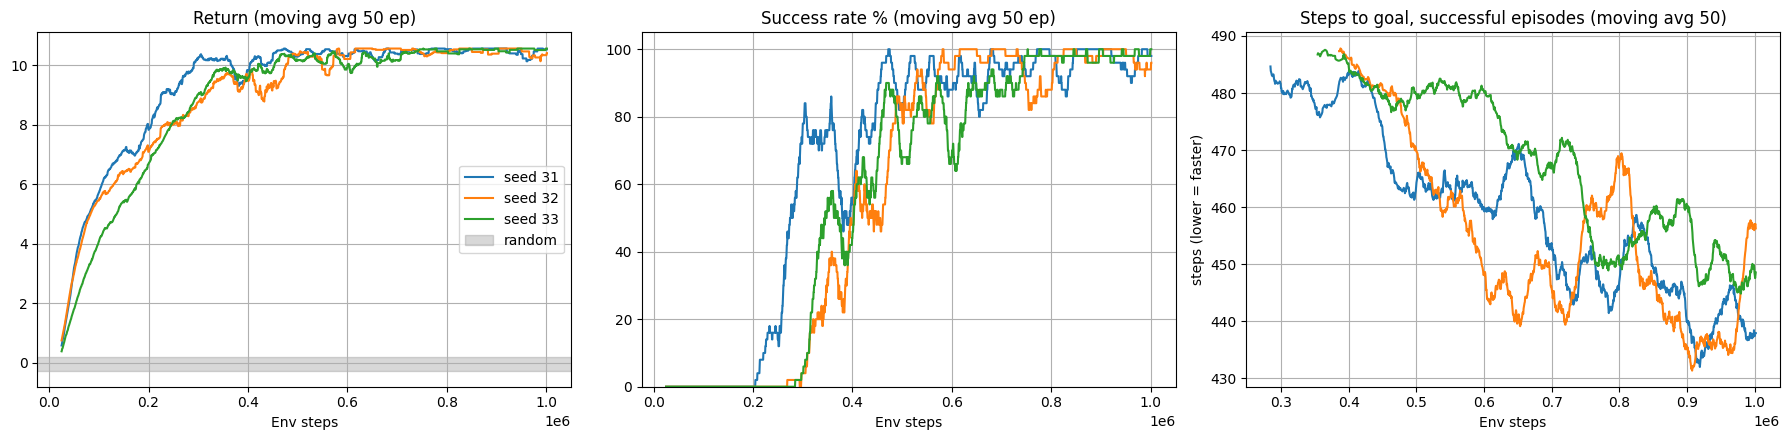

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for s, color in zip(SEEDS, ["tab:blue", "tab:orange", "tab:green"]):
    ep, lg = runs[s]
    axes[0].plot(ep["end_step"], ep["episode_return"].rolling(50).mean(), color=color, label=f"seed {s}")
    axes[1].plot(ep["end_step"], 100 * ep["success"].rolling(50).mean(), color=color)
    succ = ep[ep["success"]]
    axes[2].plot(succ["end_step"], succ["length"].rolling(50).mean(), color=color)
axes[0].axhspan(random_mean - random_std, random_mean + random_std, color="gray", alpha=0.3, label="random")
axes[0].set(title="Return (moving avg 50 ep)", xlabel="Env steps"); axes[0].legend()
axes[1].set(title="Success rate % (moving avg 50 ep)", xlabel="Env steps", ylim=(0, 105))
axes[2].set(title="Steps to goal, successful episodes (moving avg 50)", xlabel="Env steps", ylabel="steps (lower = faster)")
for ax in axes: ax.grid(True)
plt.tight_layout(); plt.savefig("../figures/03_walker_baseline_3seeds.png", dpi=120); plt.show()

## Observation scale

The observation is `[centre-of-mass velocity (2), relative positions of the robot's 36 points (72)]`. Collected over 3 episodes with the trained (stochastic) policy:

In [7]:
ag = PPOAgent(state_size=74, action_size=int((body >= 3).sum()))
ag.network.load_state_dict(torch.load(Path("../runs/walker_baseline_s31") / "model.pt"))
sigma = ag.network.log_std.detach().exp().numpy()
env, rng, O = make_env("Walker-v0", {"body": body}), np.random.default_rng(0), []
for seed in range(3):
    s, _ = env.reset(seed=seed)
    done = False
    while not done:
        O.append(s)
        with torch.no_grad():
            mean = ag.network(torch.as_tensor(s, dtype=torch.float32).unsqueeze(0))[0].numpy()[0]
        s, r, terminated, truncated, _ = env.step(to_env_action(mean + sigma * rng.standard_normal(len(sigma)), env.action_space))
        done = terminated or truncated
env.close()
O = np.array(O)
for name, sl in [("velocity (2 dims)", slice(0, 2)), ("relative positions (72 dims)", slice(2, 74))]:
    X = O[:, sl]
    print(f"{name:28}: mean |x| = {np.abs(X).mean():.3f}, std per dim {X.std(0).min():.4f} .. {X.std(0).max():.4f}")

Using device: cpu


velocity (2 dims)           : mean |x| = 4.321, std per dim 1.6874 .. 2.4982
relative positions (72 dims): mean |x| = 0.155, std per dim 0.0091 .. 0.1159


## Diagnosis → experiments for step 4

**Baseline reference (3 seeds, mean ± std)** — saved in `results/baseline_walker_summary.csv`:

| Metric | Baseline |
|---|---|
| Return, last 100 episodes | 10.46 ± 0.11 (max ≈ 10.5) |
| Success rate, last 100 episodes | 97.3 ± 2.1 % |
| Steps to goal, last 100 successful training episodes | 445.5 ± 5.7 |
| Steps to goal, deterministic test | 404 ± 25 |
| Training steps to 90 % success | 482k ± 39k |

**What we learn:**
- **Robust:** the three seeds all learn and all reach the goal (95–99 % success). The baseline is not a lucky seed.
- **The return is saturated, the speed is not:** steps-to-goal is still decreasing at 1M steps (≈ 485 → 440). The robot keeps getting faster; this is where the room for improvement is.
- **Learning only "clicks" late:** no episode reaches the goal before ≈ 200–300k steps, and 90 % success takes ≈ 480k steps.

| Observation | Hypothesis | Experiment (step 4) | Metric to watch |
|---|---|---|---|
| Tiny rewards (≈ 0.02 per step), opposite of Pendulum | the critic fits values of very small and drifting scale | **reward normalisation** (worked on Pendulum) | training steps to 90 % success, steps to goal |
| Inputs on very different scales: velocity ≈ 4.3, positions ≈ 0.15 (some vary by only 0.009), a factor 30–250 | small but important posture signals are drowned by the velocity | **observation normalisation** | same |
| Critic loss keeps rising after 200k steps while the actor improves | actor and critic compete in the shared trunk | **separate actor and critic networks** | critic loss, steps to goal |
| σ only goes from 1.0 to 0.85, noisy behaviour and occasional falls | exploration stays too high late in training | **lower initial σ or entropy schedule** | success rate, steps to goal |

Protocol for each experiment: **one change at a time**, 3 seeds (31–33), 1M steps, compared with this table.